In [37]:
from langgraph.graph import StateGraph, START ,END
from typing import TypedDict,Literal

In [38]:
class QUADSTATE(TypedDict):
    a : int
    b :int
    c :int

    equation : str
    discremenat : float
    result : str


In [39]:
def show_equation(state: QUADSTATE):
    equation = f'{state["a"]}x² + {state["b"]}x + {state["c"]}'

    return {'equation': equation}


def calculate_discremenant(state: QUADSTATE):
    discremenant = state["b"]**2 - (4 * state["a"] * state["c"])

    return {'discremenant': discremenant}

def real_rots(state: QUADSTATE):
    root1 = (-state["b"] + state["discremenant"]**0.5) / (2 * state["a"])
    root2 = (-state["b"] - state["discremenant"]**0.5) / (2 * state["a"])

    result = f"The roots are {root1} and {root2}"

    return {"result": result}

def repeated_rots(state: QUADSTATE):

    root = (-state["b"]) / (2 * state["a"])

    result = f'Only repeating root is {root}'

    return {"result": result}


def no_real_rots(state: QUADSTATE):

    result = f'No real roots'

    return {"result": result}

def check_condition (state:QUADSTATE) ->Literal['real_rots','repeated_rots','no_real_rots']:
    if state['discremennat']>0:
        return  'real_rots'
    elif state['discremenant']==0:
        return 'repeated_rots'
    else:
        return 'no_real_rots'





In [40]:
graph = StateGraph(QUADSTATE)

graph.add_node('show_equation', show_equation)
graph.add_node('calculate_discremenant', calculate_discremenant)
graph.add_node('real_rots',real_rots)
graph.add_node('repeated_rots',repeated_rots)
graph.add_node('no_real_rots',no_real_rots)

graph.add_edge(START, 'show_equation')
graph.add_edge('show_equation', 'calculate_discremenant')
graph.add_conditional_edges(
    'calculate_discremenant',
    check_condition
)
graph.add_edge('real_rots', END)
graph.add_edge('repeated_rots', END)
graph.add_edge('no_real_rots', END)

work_flow = graph.compile()

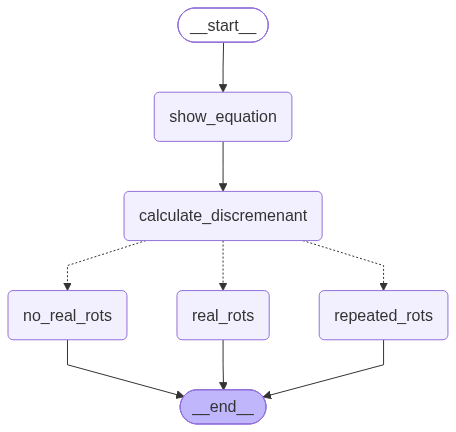

In [41]:
work_flow

In [1]:
from typing import TypedDict, Literal
from langgraph.graph import StateGraph, START, END


# ==========================================
# STATE
# ==========================================

class QUADSTATE(TypedDict):
    a: int
    b: int
    c: int

    equation: str
    discremenant: float
    result: str


# ==========================================
# NODE 1: SHOW EQUATION
# ==========================================

def show_equation(state: QUADSTATE):

    equation = f'{state["a"]}x² + {state["b"]}x + {state["c"]}'

    return {
        'equation': equation
    }


# ==========================================
# NODE 2: CALCULATE DISCRIMINANT
# ==========================================

def calculate_discremenant(state: QUADSTATE):

    discremenant = state["b"]**2 - (
        4 * state["a"] * state["c"]
    )

    return {
        'discremenant': discremenant
    }


# ==========================================
# NODE 3: REAL ROOTS
# ==========================================

def real_rots(state: QUADSTATE):

    root1 = (
        -state["b"] + state["discremenant"]**0.5
    ) / (2 * state["a"])

    root2 = (
        -state["b"] - state["discremenant"]**0.5
    ) / (2 * state["a"])

    result = f"The roots are {root1} and {root2}"

    return {
        "result": result
    }


# ==========================================
# NODE 4: REPEATED ROOT
# ==========================================

def repeated_rots(state: QUADSTATE):

    root = (-state["b"]) / (2 * state["a"])

    result = f"Only repeating root is {root}"

    return {
        "result": result
    }


# ==========================================
# NODE 5: NO REAL ROOTS
# ==========================================

def no_real_rots(state: QUADSTATE):

    result = "No real roots"

    return {
        "result": result
    }


# ==========================================
# CONDITIONAL FUNCTION
# ==========================================

def check_condition(
    state: QUADSTATE
) -> Literal[
    'real_rots',
    'repeated_rots',
    'no_real_rots'
]:

    if state['discremenant'] > 0:

        return 'real_rots'

    elif state['discremenant'] == 0:

        return 'repeated_rots'

    else:

        return 'no_real_roots'


# ==========================================
# CREATE GRAPH
# ==========================================

graph = StateGraph(QUADSTATE)


# ==========================================
# ADD NODES
# ==========================================

graph.add_node(
    'show_equation',
    show_equation
)

graph.add_node(
    'calculate_discremenant',
    calculate_discremenant
)

graph.add_node(
    'real_rots',
    real_rots
)

graph.add_node(
    'repeated_rots',
    repeated_rots
)

graph.add_node(
    'no_real_rots',
    no_real_rots
)


# ==========================================
# ADD EDGES
# ==========================================

graph.add_edge(
    START,
    'show_equation'
)

graph.add_edge(
    'show_equation',
    'calculate_discremenant'
)


# ==========================================
# CONDITIONAL EDGE
# ==========================================

graph.add_conditional_edges(
    'calculate_discremenant',
    check_condition
)


# ==========================================
# END EDGES
# ==========================================

graph.add_edge(
    'real_rots',
    END
)

graph.add_edge(
    'repeated_rots',
    END
)

graph.add_edge(
    'no_real_rots',
    END
)


# ==========================================
# COMPILE GRAPH
# ==========================================

work_flow = graph.compile()


# ==========================================
# INITIAL STATE
# ==========================================

initial_state = {
    'a': 3,
    'b': 21,
    'c': 9
}


# ==========================================
# INVOKE
# ==========================================

result = work_flow.invoke(initial_state)


# ==========================================
# OUTPUT
# ==========================================

print(result)

{'a': 3, 'b': 21, 'c': 9, 'equation': '3x² + 21x + 9', 'discremenant': 333, 'result': 'The roots are -0.45861873485089016 and -6.54138126514911'}
